In [1]:
%load_ext autoreload

import logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s') # NOTSET, DEBUG, INFO, WARN, ERROR, CRITICAL

import os
import numpy as np

os.environ["JAX_PLATFORM_NAME"] = "cpu"  # must be set before importing jax

import jax
import jax.numpy as jnp
from jax import vmap, jit, grad, jacfwd

from itertools import combinations, product as cartesian_product
from scipy.fft import rfft, rfftfreq, irfft

import skewerjax as sjx

import matplotlib as mpl
from matplotlib.collections import LineCollection
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
plt.style.use('tableau-colorblind10')
font, rcnew = sjx.config.setup_matplotlib.matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)
%matplotlib widget

INFO:2026-05-09 15:44:17,010:jax._src.xla_bridge:752: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
2026-05-09 15:44:17,010 - INFO - Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
2026-05-09 15:44:17,358 - INFO - SkewerBundle class definition complete


In [2]:
seed = 137 
N_samples = 16
Npix = 512
L_box = 100

delta_v_list = [0.0, L_box / 8]

In [3]:
dv = L_box / Npix
v = np.arange(Npix) * dv

rng = np.random.default_rng(seed)

In [4]:
# ------------ generate gaussian tau field ------------ #

def pk_template(k, A, n, k0, k_cut):
    kk = np.maximum(k, 1e-12)
    return A * (kk / k0) ** n * np.exp(-(kk / k_cut) ** 2)

pk_func = lambda k: pk_template(k, A=1.0, n=2.0, k0=2.0 * np.pi / L_box, k_cut=30.0 * 2.0 * np.pi / L_box)

gen = sjx.skewers.toy_skewers.ShiftedGaussianTauGenerator1D(
    Npix=Npix, L_box=L_box, delta_v_list=delta_v_list, pk_func=pk_func, mean_tau=1.0, contrast=0.35,
)

tau_fields = gen.sample(N_samples=N_samples, seed=seed)

# ------------ generate shifted spike tau field ------------ #

n_pairs = 3
sigma_list = [L_box / 1000, L_box / 1000]
amplitude_list = [10.0, 10.0]
gen = sjx.skewers.toy_skewers.ShiftedSpikeTauGenerator1D(
    Npix=Npix, L_box=L_box, delta_v_list=delta_v_list, sigma_list=sigma_list, amplitude_list=amplitude_list, n_pairs=n_pairs,
)
tau_fields = gen.sample(N_samples=N_samples, seed=seed)

In [5]:
x_fields = np.exp(-tau_fields)

x1 = x_fields[:, 0]
x2 = x_fields[:, 1]
x = np.prod(x_fields, axis=1)

x1_mean = np.mean(x1, axis=1, keepdims=True)
x2_mean = np.mean(x2, axis=1, keepdims=True)
x_mean = np.mean(x, axis=1, keepdims=True)

delta_x1 = x1 / x1_mean - 1.0
delta_x2 = x2 / x2_mean - 1.0
delta_x = x / x_mean - 1.0

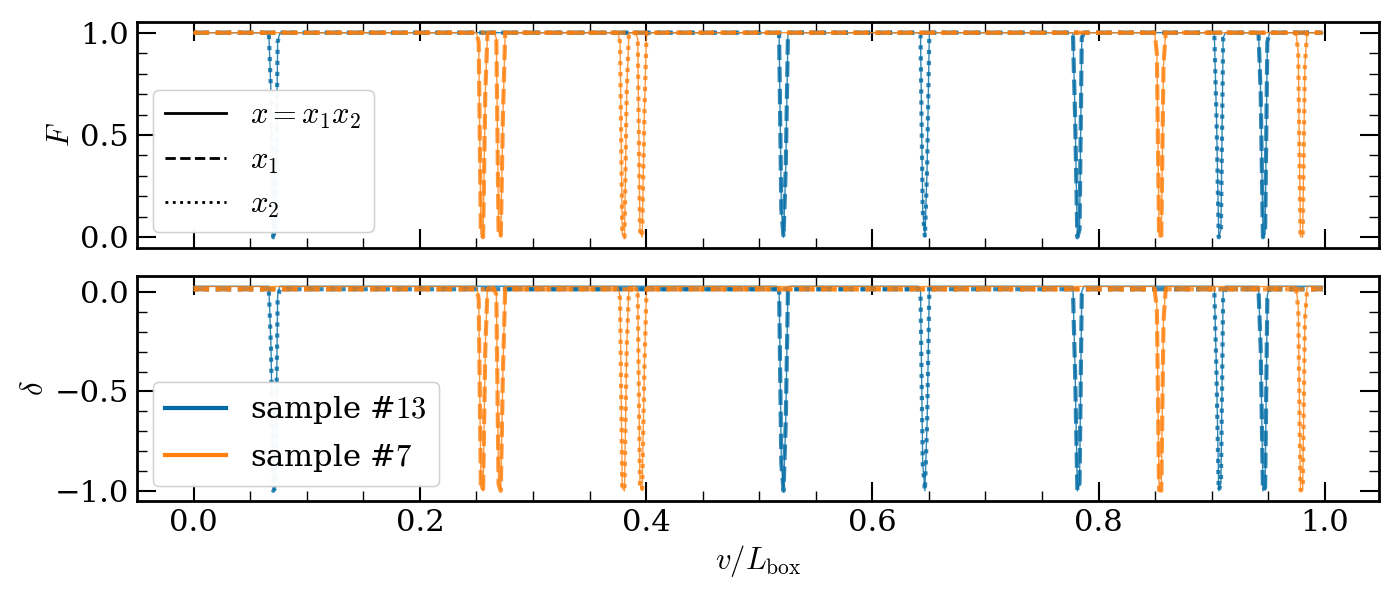

In [6]:
idx = rng.choice(N_samples, size=2, replace=False)
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

fig, axes = plt.subplots(figsize=(14, 6), nrows=2, ncols=1, sharex=True)

for j, i in enumerate(idx):
    c = colors[j % len(colors)]

    axes[0].plot(v / L_box, x[i],  lw=1.0, alpha=0.8, color=c, ls="-")
    axes[0].plot(v / L_box, x1[i], lw=3.0, alpha=0.8, color=c, ls="--")
    axes[0].plot(v / L_box, x2[i], lw=3.0, alpha=0.8, color=c, ls=":")

    axes[1].plot(v / L_box, delta_x[i],  lw=1.0, alpha=0.8, color=c, ls="-")
    axes[1].plot(v / L_box, delta_x1[i], lw=3.0, alpha=0.8, color=c, ls="--")
    axes[1].plot(v / L_box, delta_x2[i], lw=3.0, alpha=0.8, color=c, ls=":")

axes[0].set_ylabel(r"$F$", fontsize=22)
axes[0].tick_params(axis="both", labelsize=22)

axes[1].set_xlabel(r"$v / L_\mathrm{box}$", fontsize=22)
axes[1].set_ylabel(r"$\delta$", fontsize=22)
axes[1].tick_params(axis="both", labelsize=22)

# Legend for line styles
style_legend = [
    Line2D([0], [0], color="k", lw=2.0, ls="-",  label=r"$x = x_1 x_2$"),
    Line2D([0], [0], color="k", lw=2.0, ls="--", label=r"$x_1$"),
    Line2D([0], [0], color="k", lw=2.0, ls=":",  label=r"$x_2$"),
]

# Legend for selected sample indices
sample_legend = [
    Line2D([0], [0], color=colors[j % len(colors)], lw=3.0, ls="-", label=fr"sample #${i}$") for j, i in enumerate(idx)
]

leg1 = axes[0].legend(handles=style_legend, fontsize=22, loc="lower left")
axes[0].add_artist(leg1)
leg2 = axes[1].legend(handles=sample_legend, fontsize=22, loc="lower left")
axes[1].add_artist(leg2)

plt.tight_layout()
plt.show()

In [7]:
k = 2.0 * np.pi * rfftfreq(Npix, d=dv)
k_norm = k * L_box / (2.0 * np.pi)

fk = rfft(delta_x, axis=1)
Pk_per_sample = (dv / Npix) * (fk * fk.conj())
Pk = np.mean(Pk_per_sample, axis=0).real

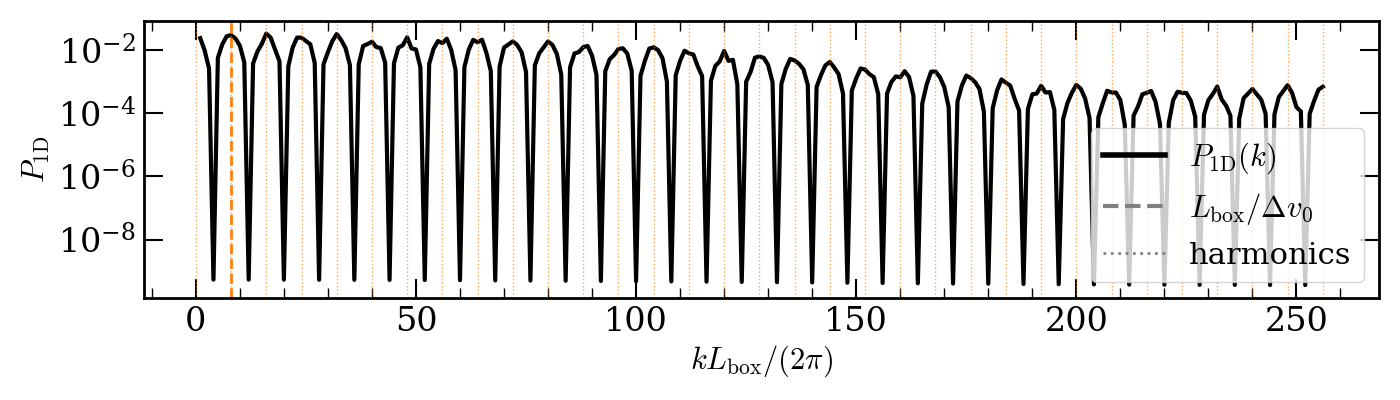

In [8]:
fig, ax = plt.subplots(figsize=(14, 4))

# Total P1D
ax.plot(k_norm[1:], Pk[1:], lw=3.0, color="black")

# Fundamental mode and harmonics
for j, delta_v_0 in enumerate(delta_v_list):
    if delta_v_0 != 0.0:
        c = colors[j % len(colors)]
        k0_norm = L_box / delta_v_0   # Characteristic frequency from Delta v_0
        n_max_harmonic = int(np.floor((Npix / 2) / k0_norm))

        ax.axvline(k0_norm, color=c, lw=2.0, ls="--")
        for n in range(0, n_max_harmonic + 1):
            ax.axvline(n * k0_norm, color=c, lw=1.0, ls=":", alpha=0.7)

# Custom legend
legend_handles = [
    Line2D([0], [0], color="black", lw=4.0, ls="-",  label=r"$P_{\rm 1D}(k)$"),
    Line2D([0], [0], color="grey", lw=3.0, ls="--", label=r"$L_{\rm box}/\Delta v_0$"),
    Line2D([0], [0], color="grey", lw=2.0, ls=":",  label=r"harmonics"),
]

ax.set_yscale("log")
ax.set_xlabel(r"$kL_\mathrm{box}/(2\pi)$", fontsize=22)
ax.set_ylabel(r"$P_{\rm 1D}$", fontsize=22)
ax.legend(handles=legend_handles, fontsize=22)

plt.tight_layout()
plt.show()

In [9]:
lags = (np.arange(Npix) - Npix // 2) * dv
lags_norm = lags / L_box

lags_per = np.arange(Npix) * dv
lags_per_norm = lags_per / L_box

# Xi from inverse FFT of the total P1D
xi_per_sample = irfft(Pk_per_sample, n=Npix, axis=1) / dv
xi = np.mean(xi_per_sample, axis=0).real
xi_plot = np.fft.fftshift(xi)

# Function to compute the direct periodic Xi1D
def Xi1D_direct_periodic(x):
    N, Npix = x.shape
    xi = np.empty((N, Npix), dtype=float)
    for lag in range(Npix):
        xi[:, lag] = np.mean(x * np.roll(x, -lag, axis=1), axis=1)
    return xi

# Direct periodic Xi
xi_direct_per_sample = Xi1D_direct_periodic(delta_x)
xi_direct = np.mean(xi_direct_per_sample, axis=0)

/home/dlopez/tmp/pip-tmp/ipykernel_1559756/1498560136.py:53: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


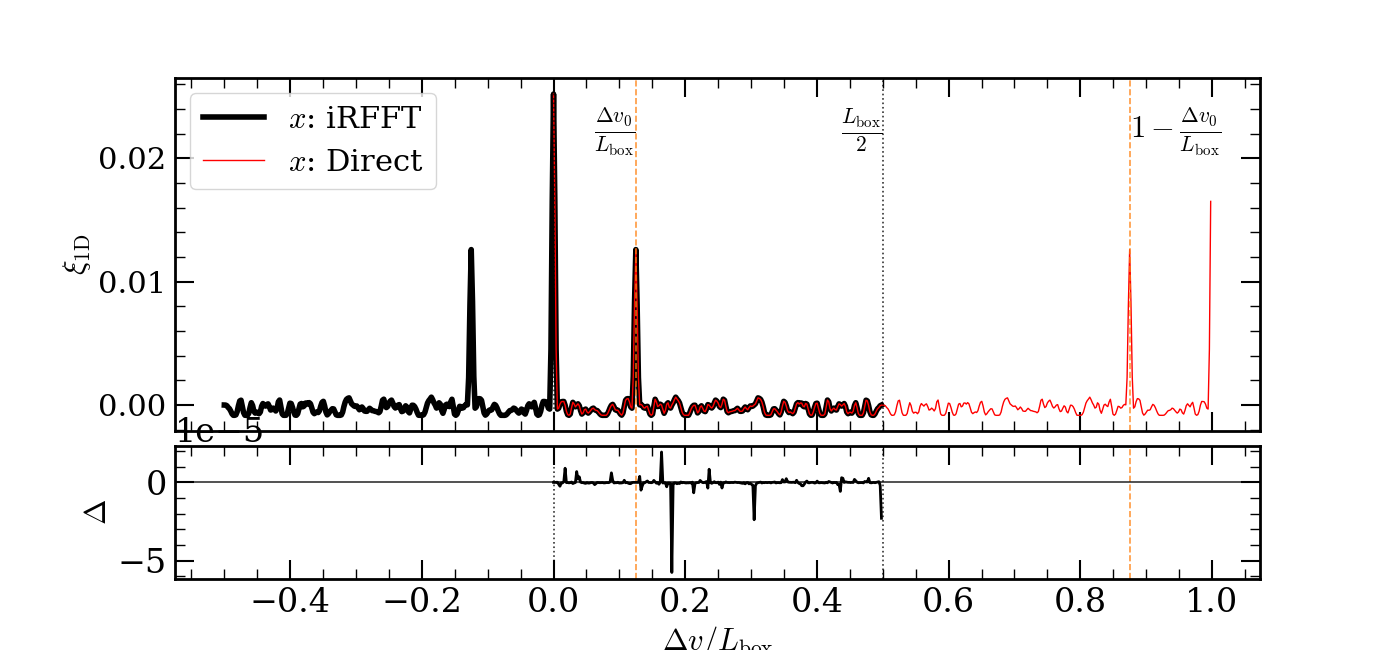

In [10]:
fig = plt.figure(figsize=(14, 6.5))
gs = fig.add_gridspec(nrows=2, ncols=1, height_ratios=[3.2, 1.2], hspace=0.06)

ax = fig.add_subplot(gs[0])
ax_res = fig.add_subplot(gs[1], sharex=ax)

# Main panel
ax.plot(lags_norm, xi_plot, lw=4.0, color="k", label=r"$x$: iRFFT")
ax.plot(lags_per_norm, xi_direct, lw=1.0, color="red", ls="-", label=r"$x$: Direct")

ax.axvline(0.0, color="k", lw=1.2, alpha=0.8, ls=":")
ax.axvline(0.5, color="k", lw=1.2, alpha=0.8, ls=":")

for j, delta_v_0 in enumerate(delta_v_list):
    if delta_v_0 != 0.0:
        c = colors[j % len(colors)]

        ax.axvline(delta_v_0 / L_box, color=c, lw=1.2, alpha=0.8, ls="--")
        ax.axvline(1.0 - delta_v_0 / L_box, color=c, lw=1.2, alpha=0.8, ls="--")
        ymin, ymax = ax.get_ylim()
        ytext = ymin + 0.92 * (ymax - ymin)
        ax.text(0.5, ytext, r"$\frac{L_\mathrm{box}}{2}$", ha="right", va="top", fontsize=22)
        ax.text(delta_v_0 / L_box, ytext, r"$\frac{\Delta v_0}{L_\mathrm{box}}$", ha="right", va="top", fontsize=22)
        ax.text(1.0 - delta_v_0 / L_box, ytext, r"$1-\frac{\Delta v_0}{L_\mathrm{box}}$", ha="left", va="top", fontsize=22)

        ax_res.axvline(delta_v_0 / L_box, color=c, lw=1.2, alpha=0.8, ls="--")
        ax_res.axvline(1.0 - delta_v_0 / L_box, color=c, lw=1.2, alpha=0.8, ls="--")

ax.set_ylabel(r"$\xi_{\rm 1D}$", fontsize=22)
ax.tick_params(axis="both", labelsize=22, labelbottom=False)
ax.legend(fontsize=22)

# Residual panel: only over common domain 0 <= lag < 1/2
mask_ifft = lags_norm >= 0.0
x_overlap = lags_norm[mask_ifft]
xi_ifft_overlap = xi_plot[mask_ifft]

xi_direct_overlap = xi_direct[:len(x_overlap)]
xi_floor = 1e-12 * np.max(np.abs(xi_ifft_overlap)) + 1e-15
xi_den = np.maximum(np.abs(xi_ifft_overlap), xi_floor)
xi_residual = (xi_direct_overlap - xi_ifft_overlap) / xi_den

ax_res.plot(x_overlap, xi_residual, lw=2.0, color="black")

ax_res.fill_between(x_overlap, -1e-13, 1e-13, color="gray", alpha=0.25, zorder=0)
ax_res.axhline(0.0, color="k", lw=1.2, alpha=0.8)
ax_res.axvline(0.0, color="k", lw=1.2, alpha=0.8, ls=":")
ax_res.axvline(0.5, color="k", lw=1.2, alpha=0.8, ls=":")

ax_res.set_xlabel(r"$\Delta v / L_\mathrm{box}$", fontsize=22)
ax_res.set_ylabel(r"$\Delta$", fontsize=22)

plt.tight_layout()
plt.show()

# Sliders

In [11]:
import ipywidgets as widgets
from IPython.display import display

In [12]:
# ------------------------------------------------------------
# Fixed parameters
# ------------------------------------------------------------
seed = 137
N_samples = 16
Npix = 512
L_box = 100.0

n_pairs = 3
amplitude_list = [10.0, 10.0]

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

# ------------------------------------------------------------
# Main plotting function Sliders
# ------------------------------------------------------------
def plot_toy_model(delta_frac=1/8, sigma1_frac=1/1000, sigma2_frac=1/1000):
    delta_v_2 = L_box * delta_frac
    sigma1 = L_box * sigma1_frac
    sigma2 = L_box * sigma2_frac

    dv = L_box / Npix
    v = np.arange(Npix) * dv

    rng = np.random.default_rng(seed)

    # -------- generate shifted spike tau field -------- #
    delta_v_list = [0.0, delta_v_2]
    sigma_list = [sigma1, sigma2]

    gen = sjx.skewers.toy_skewers.ShiftedSpikeTauGenerator1D(
        Npix=Npix, L_box=L_box, delta_v_list=delta_v_list, sigma_list=sigma_list, amplitude_list=amplitude_list, n_pairs=n_pairs,
    )
    tau_fields = gen.sample(N_samples=N_samples, seed=seed)

    x_fields = np.exp(-tau_fields)

    x1 = x_fields[:, 0]
    x2 = x_fields[:, 1]
    x = np.prod(x_fields, axis=1)

    x1_mean = np.mean(x1, axis=1, keepdims=True)
    x2_mean = np.mean(x2, axis=1, keepdims=True)
    x_mean = np.mean(x, axis=1, keepdims=True)

    delta_x1 = x1 / x1_mean - 1.0
    delta_x2 = x2 / x2_mean - 1.0
    delta_x = x / x_mean - 1.0

    # ============================================================
    # Figure 1: sample fields
    # ============================================================
    idx = rng.choice(N_samples, size=2, replace=False)

    fig, ax = plt.subplots(figsize=(14, 4))

    for j, i in enumerate(idx):
        c = colors[j % len(colors)]

        ax.plot(v / L_box, x[i],  lw=1.0, alpha=0.8, color=c, ls="-")
        ax.plot(v / L_box, x1[i], lw=3.0, alpha=0.8, color=c, ls="--")
        ax.plot(v / L_box, x2[i], lw=3.0, alpha=0.8, color=c, ls=":")

    ax.set_ylabel(r"$F$", fontsize=22)
    ax.tick_params(axis="both", labelsize=22)

    ax.set_xlabel(r"$v / L_\mathrm{box}$", fontsize=22)
    ax.tick_params(axis="both", labelsize=22)

    style_legend = [
        Line2D([0], [0], color="k", lw=2.0, ls="-",  label=r"$x = x_1 x_2$"),
        Line2D([0], [0], color="k", lw=2.0, ls="--", label=r"$x_1$"),
        Line2D([0], [0], color="k", lw=2.0, ls=":",  label=r"$x_2$"),
    ]

    sample_legend = [
        Line2D([0], [0], color=colors[j % len(colors)], lw=3.0, ls="-", label=fr"sample #${i}$") for j, i in enumerate(idx)
    ]

    leg1 = ax.legend(handles=style_legend, fontsize=18, loc="lower left")
    ax.add_artist(leg1)
    leg2 = ax.legend(handles=sample_legend, fontsize=18, loc="lower right")
    ax.add_artist(leg2)

    fig.suptitle(
        fr"$\Delta v_2/L_\mathrm{{box}}={delta_frac:.4g}$, "
        fr"$\sigma_1/L_\mathrm{{box}}={sigma1_frac:.4g}$, "
        fr"$\sigma_2/L_\mathrm{{box}}={sigma2_frac:.4g}$",
        fontsize=18
    )
    plt.show()

    # ============================================================
    # Figure 2: P1D
    # ============================================================
    k = 2.0 * np.pi * rfftfreq(Npix, d=dv)
    k_norm = k * L_box / (2.0 * np.pi)

    fk = rfft(delta_x, axis=1)
    Pk_per_sample = (dv / Npix) * (fk * fk.conj())
    Pk = np.mean(Pk_per_sample, axis=0).real

    fig, ax = plt.subplots(figsize=(14, 4))
    ax.plot(k_norm[1:], Pk[1:], lw=3.0, color="black")

    for j, delta_v_0 in enumerate(delta_v_list):
        if delta_v_0 != 0.0:
            c = colors[j % len(colors)]
            k0_norm = L_box / delta_v_0   # Characteristic frequency from Delta v_0
            n_max_harmonic = int(np.floor((Npix / 2) / k0_norm))

            ax.axvline(k0_norm, color=c, lw=2.0, ls="--")
            for n in range(0, n_max_harmonic + 1):
                ax.axvline(n * k0_norm, color=c, lw=1.0, ls=":", alpha=0.7)

    legend_handles = [
        Line2D([0], [0], color="black", lw=3.0, ls="-",  label=r"$P_{\rm 1D}(k)$"),
        Line2D([0], [0], color="black", lw=2.0, ls="--", label=r"$L_{\rm box}/\Delta v_2$"),
        Line2D([0], [0], color="black", lw=1.2, ls=":",  label=r"harmonics"),
    ]

    ax.set_yscale("log")
    ax.set_xlabel(r"$kL_\mathrm{box}/(2\pi)$", fontsize=22)
    ax.set_ylabel(r"$P_{\rm 1D}$", fontsize=22)
    ax.tick_params(axis="both", labelsize=22)
    ax.legend(handles=legend_handles, fontsize=18)
    plt.show()

    # ============================================================
    # Figure 3: Xi1D
    # ============================================================
    lags = (np.arange(Npix) - Npix // 2) * dv
    lags_norm = lags / L_box

    # Xi from inverse FFT of the total P1D
    xi_per_sample = irfft(Pk_per_sample, n=Npix, axis=1) / dv
    xi = np.mean(xi_per_sample, axis=0).real
    xi_plot = np.fft.fftshift(xi)

    fig, ax = plt.subplots(figsize=(14, 4))

    ax.plot(lags_norm, xi_plot, lw=4.0, color="k")

    ax.axvline(0.0, color="k", lw=1.2, alpha=0.8, ls=":")
    ax.axvline(0.5, color="k", lw=1.2, alpha=0.8, ls=":")

    for j, delta_v_0 in enumerate(delta_v_list):
        if delta_v_0 != 0.0:
            c = colors[j % len(colors)]

            ax.axvline(delta_v_0 / L_box, color=c, lw=1.2, alpha=0.8, ls="--")
            ax.axvline(1.0 - delta_v_0 / L_box, color=c, lw=1.2, alpha=0.8, ls="--")
            ymin, ymax = ax.get_ylim()
            ytext = ymin + 0.92 * (ymax - ymin)
            ax.text(0.5, ytext, r"$\frac{L_\mathrm{box}}{2}$", ha="right", va="top", fontsize=22)
            ax.text(delta_v_0 / L_box, ytext, r"$\frac{\Delta v_0}{L_\mathrm{box}}$", ha="right", va="top", fontsize=22)
            ax.text(1.0 - delta_v_0 / L_box, ytext, r"$1-\frac{\Delta v_0}{L_\mathrm{box}}$", ha="left", va="top", fontsize=22)

    ax.set_xlim(-0.01, 0.51)

    ymin, ymax = ax.get_ylim()
    ytext = ymin + 0.92 * (ymax - ymin)
    ax.text(0.5, ytext, r"$\frac{L_\mathrm{box}}{2}$", ha="right", va="top", fontsize=22)
    ax.text(delta_frac, ytext, r"$\frac{\Delta v_2}{L_\mathrm{box}}$", ha="right", va="top", fontsize=22)
    ax.text(1.0 - delta_frac, ytext, r"$1-\frac{\Delta v_2}{L_\mathrm{box}}$", ha="left", va="top", fontsize=22)

    ax.set_ylabel(r"$\xi_{\rm 1D}$", fontsize=22)
    ax.set_xlabel(r"$\Delta v / L_\mathrm{box}$", fontsize=22)
    ax.tick_params(axis="both", labelsize=22)

    plt.show()

In [13]:
delta_slider = widgets.FloatSlider(
    value=1/8, min=0.0, max=0.48, step=1 / Npix, description=r"Δv/L", readout_format=".4f",
    continuous_update=False
)

sigma1_slider = widgets.FloatLogSlider(
    value=1/500, base=10, min=-4.0, max=-2.0,      # 1e-2
    step=0.05, description=r"σ1/L", readout_format=".4f", continuous_update=False
)

sigma2_slider = widgets.FloatLogSlider(
    value=1/500, base=10, min=-4.0, max=-2.0,
    step=0.05, description=r"σ2/L", readout_format=".4f", continuous_update=False,
)

ui = widgets.VBox([delta_slider, sigma1_slider, sigma2_slider])

out = widgets.interactive_output(
    plot_toy_model, {"delta_frac": delta_slider, "sigma1_frac": sigma1_slider, "sigma2_frac": sigma2_slider},
)

display(ui, out)

Output()